# Objective 2 - Product segmentation

The second half of Objective 2. Where the forecasting notebook asks *how much* the shop
will sell, this one asks *what* it sells, and groups the catalogue into segments a buyer
could actually act on.

## Why products and not customers

The usual segmentation for a retail dataset is RFM on customers - recency, frequency,
monetary value, grouped per person. **That cannot be done here.** The sales data carries no
customer identifier of any kind:

`saleId, lineNo, date, year, month, orderType, paymentMethod, sku, itemType, itemName,
category, brand, quantity, unitPrice, lineTotal`

Every receipt is anonymous, and nothing links two receipts to the same buyer. RFM needs to
group transactions by customer, so it has no input here. Customer-level segmentation would
have to run against the live shop's order accounts, which is Objective 1's data, not this.

What the data *does* support is segmentation of the **447 products**, on how expensive they
are, how fast they move, and whether they are still selling. For a parts shop deciding what
to restock and what to clear, that is the more useful question anyway.

**Type of learning:** unsupervised (clustering). There is no target variable - unlike the
forecasting notebook, nothing here is being predicted.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

lines = pd.read_csv("data/processed/sales_lines_products.csv", parse_dates=["date"])
as_of = lines.date.max()
print(f"{len(lines):,} product lines, {lines.sku.nunique()} SKUs, as of {as_of:%Y-%m-%d}")

39,751 product lines, 447 SKUs, as of 2026-08-31


## One row per product

Four behavioural features, chosen so each says something the others do not:

| Feature | What it captures |
|---|---|
| `avg_price` | how expensive the product is |
| `units` | how fast it moves |
| `recency_wk` | weeks since it last sold - is it still alive |
| `active_wk` | weeks between first and last sale - how long it has been in the range |

Revenue is deliberately *excluded* from the clustering. Revenue is roughly price x units, so
feeding it in alongside both would count the same information twice and let the biggest
sellers dominate the geometry. It is kept for interpreting the clusters afterwards.

In [2]:
products = lines.groupby("sku").agg(
    name      = ("itemName", "first"),
    category  = ("category", "first"),
    revenue   = ("lineTotal", "sum"),
    units     = ("quantity", "sum"),
    receipts  = ("saleId", "nunique"),
    avg_price = ("unitPrice", "mean"),
    first_sale= ("date", "min"),
    last_sale = ("date", "max"),
)
products["recency_wk"] = (as_of - products.last_sale).dt.days / 7
products["active_wk"]  = (products.last_sale - products.first_sale).dt.days / 7
products["rev_share%"] = products.revenue / products.revenue.sum() * 100

print(f"{len(products)} products")
display(products[["revenue","units","receipts","avg_price","recency_wk","active_wk"]]
        .describe().loc[["min","25%","50%","75%","max"]])

447 products


,revenue,units,receipts,avg_price,recency_wk,active_wk
min,"1,608.3",1.0,1.0,9.4,0.0,0.0
25%,"14,372.4",15.0,12.0,232.2,2.3,99.6
50%,"26,969.6",47.0,36.0,506.0,8.4,203.0
75%,"48,118.1",183.5,123.0,"1,468.8",28.1,237.1
max,"335,003.6","1,068.0",668.0,"8,120.6",219.0,243.3


### Scaling

`avg_price` and `units` span three orders of magnitude - a RM 9 cable against a RM 8,121
laptop - so both are log-transformed first, otherwise the expensive items alone decide the
clusters. All four features are then standardised, because K-Means measures plain Euclidean
distance and would otherwise weight whichever feature happens to have the largest numbers.

In [3]:
FEATURES = ["avg_price", "units", "recency_wk", "active_wk"]

X = products[FEATURES].copy()
X["avg_price"] = np.log10(X.avg_price)
X["units"]     = np.log10(X.units)

X_scaled = StandardScaler().fit_transform(X)
print(f"clustering matrix: {X_scaled.shape[0]} products x {X_scaled.shape[1]} features")

clustering matrix: 447 products x 4 features


## Choosing k

Two standard checks. The elbow looks for where extra clusters stop buying much reduction in
inertia; the silhouette score measures how cleanly separated the clusters are, higher being
better.

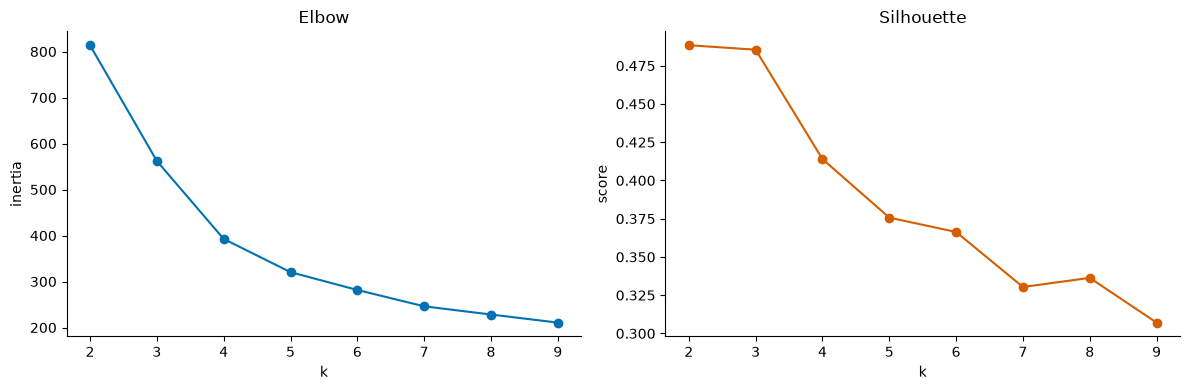

 k inertia silhouette
 2   813.9      0.488
 3   562.2      0.485
 4   392.7      0.414
 5   320.4      0.376
 6   281.7      0.366
 7   246.2      0.330
 8   228.3      0.336
 9   210.7      0.307


In [4]:
ks = range(2, 10)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertia, "o-", color="#0072B2"); ax1.set_title("Elbow"); ax1.set_xlabel("k"); ax1.set_ylabel("inertia")
ax2.plot(list(ks), silhouette, "o-", color="#D55E00"); ax2.set_title("Silhouette"); ax2.set_xlabel("k"); ax2.set_ylabel("score")
for a in (ax1, ax2): a.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

scan = pd.DataFrame({"k": list(ks),
                     "inertia": [f"{v:,.1f}" for v in inertia],
                     "silhouette": [f"{v:.3f}" for v in silhouette]})
print(scan.to_string(index=False))

**k = 4 is used below**, and the reason is worth stating honestly rather than hiding.

The silhouette score is highest at k = 2 (about 0.49) and falls as k rises. But k = 2 splits
the catalogue into little more than *cheap things* and *expensive things*, which is not a
finding - it is a price filter, and no buyer needs a clustering algorithm for it. At k = 4
the score is still respectable (about 0.41) and the groups map onto decisions a shop actually
takes: restock, clear, watch, leave alone.

Choosing k on interpretability rather than on the silhouette alone is normal practice for
segmentation, but it is a judgement call and should be presented as one.

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
products["cluster"] = kmeans.labels_

profile = products.groupby("cluster").agg(
    SKUs        = ("revenue", "size"),
    med_price   = ("avg_price", "median"),
    med_units   = ("units", "median"),
    med_recency = ("recency_wk", "median"),
    med_active  = ("active_wk", "median"),
    revenue     = ("revenue", "sum"),
)
profile["rev_share%"] = profile.revenue / products.revenue.sum() * 100
display(profile)

,SKUs,med_price,med_units,med_recency,med_active,revenue,rev_share%
cluster,,,,,,,
0,48,"1,252.2",16.0,140.4,97.4,"1,545,134.0",9.5
1,182,434.2,76.0,6.6,225.2,"8,499,743.7",52.2
2,122,"2,568.2",10.5,16.1,72.2,"2,965,419.8",18.2
3,95,69.7,369.0,2.1,240.6,"3,278,800.0",20.1


### Naming the segments

Cluster numbers from K-Means are arbitrary and change if the data or seed changes, so the
names below are derived from each cluster's own statistics rather than written against a
cluster index by hand.

In [6]:
def name_segments(profile):
    names, taken = {}, set()

    dormant = profile.med_recency.idxmax()
    names[dormant] = "Dormant / discontinued"; taken.add(dormant)

    rest = profile.drop(index=list(taken))
    fast = rest.med_units.idxmax()
    names[fast] = "Fast-moving, low value"; taken.add(fast)

    rest = profile.drop(index=list(taken))
    premium = rest.med_price.idxmax()
    names[premium] = "Premium, low volume"; taken.add(premium)

    for c in profile.index.difference(list(taken)):
        names[c] = "Core range"
    return names

segment_name = name_segments(profile)
products["segment"] = products.cluster.map(segment_name)

summary = (products.groupby("segment")
           .agg(SKUs=("revenue","size"), revenue=("revenue","sum"),
                med_price=("avg_price","median"), med_units=("units","median"),
                med_recency_wk=("recency_wk","median"))
           .sort_values("revenue", ascending=False))
summary["rev_share%"] = summary.revenue / products.revenue.sum() * 100
display(summary)

for seg in summary.index:
    top = products[products.segment == seg].nlargest(3, "revenue")
    print(f"\n{seg}")
    for _, r in top.iterrows():
        print(f"   {r['name'][:46]:46} {r.category:20} RM {r.revenue:>9,.0f}")

,SKUs,revenue,med_price,med_units,med_recency_wk,rev_share%
segment,,,,,,
Core range,182,"8,499,743.7",434.2,76.0,6.6,52.2
"Fast-moving, low value",95,"3,278,800.0",69.7,369.0,2.1,20.1
"Premium, low volume",122,"2,965,419.8","2,568.2",10.5,16.1,18.2
Dormant / discontinued,48,"1,545,134.0","1,252.2",16.0,140.4,9.5



Core range
   Asus Prime B550M-A WiFi II                     Motherboard          RM   335,004
   AMD Ryzen 7 5700X                              CPU                  RM   206,058
   MSI RTX 3050 Ventus 2X OC                      GPU                  RM   198,598

Fast-moving, low value
   Asus Prime A520M-K                             Motherboard          RM   198,944
   Slev Quantum 600 Non-modular                   PSU                  RM   105,211
   Pccooler Paladin EX400 ARGB                    Cooler               RM    93,547

Premium, low volume
   Lenovo LOQ 15IRH8 i5-12450H RTX 4050           Laptops              RM    79,512
   Lenovo IdeaPad Slim 3 15ARP10 Ryzen 7 7735HS 1 Laptops              RM    78,856
   Lenovo LOQ 15ARP10E Ryzen 7 7735HS RTX 3050    Laptops              RM    77,144

Dormant / discontinued
   HP Pavilion Desktop TP01-2020d Ryzen 5 5600G   Branded Desktops     RM   123,225
   HP Victus 16-d1178TX i5-12500H RTX 3050        Laptops              RM    95

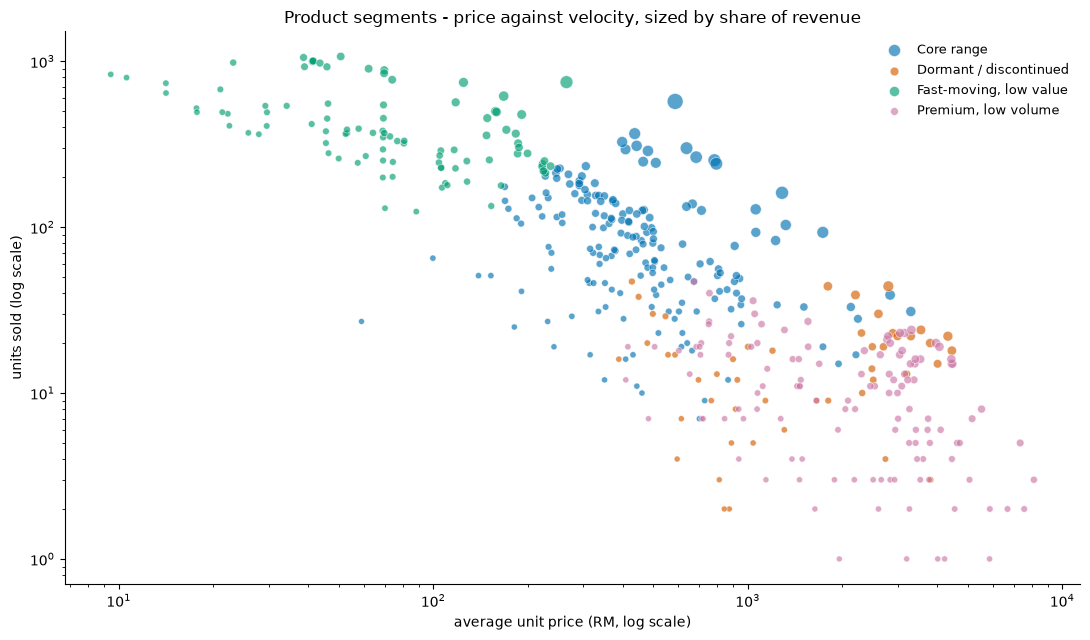

In [7]:
fig, ax = plt.subplots(figsize=(11, 6.5))
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#8c564b", "#7f7f7f"]
for i, seg in enumerate(sorted(products.segment.unique())):
    s = products[products.segment == seg]
    ax.scatter(s.avg_price, s.units, s=18 + s["rev_share%"] * 55, alpha=0.65,
               color=palette[i % len(palette)], edgecolor="white", linewidth=0.5, label=seg)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("average unit price (RM, log scale)")
ax.set_ylabel("units sold (log scale)")
ax.set_title("Product segments - price against velocity, sized by share of revenue")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

## ABC analysis, as a cross-check

Clustering groups products by *behaviour*. ABC ranks them by *contribution*, which is the
view a buyer is used to. The two answer different questions and are worth reading together.

In [8]:
abc = products.sort_values("revenue", ascending=False).copy()
abc["cum%"] = abc.revenue.cumsum() / abc.revenue.sum() * 100
abc["ABC"] = np.where(abc["cum%"] <= 80, "A", np.where(abc["cum%"] <= 95, "B", "C"))

display(abc.groupby("ABC").agg(SKUs=("revenue","size"), revenue=("revenue","sum"),
                               med_price=("avg_price","median")).assign(
        **{"SKU%": lambda d: d.SKUs / len(abc) * 100,
           "rev%": lambda d: d.revenue / abc.revenue.sum() * 100}))

print("\nsegment against ABC class (SKU counts):")
display(pd.crosstab(products.segment, abc.ABC.reindex(products.index)))

,SKUs,revenue,med_price,SKU%,rev%
ABC,,,,,
A,220,"13,018,906.0",490.9,49.2,79.9
B,123,"2,451,559.6",456.4,27.5,15.1
C,104,"818,631.9",691.4,23.3,5.0



segment against ABC class (SKU counts):


ABC,A,B,C
segment,,,
Core range,121,35,26
Dormant / discontinued,18,10,20
"Fast-moving, low value",41,38,16
"Premium, low volume",40,40,42


## Saving the assignments

In [9]:
out = products.reset_index()[["sku","name","category","segment","cluster","revenue","units",
                              "receipts","avg_price","recency_wk","active_wk","rev_share%"]]
out = out.merge(abc.reset_index()[["sku","ABC","cum%"]], on="sku", how="left")
out.to_csv("data/processed/product_segments.csv", index=False)
print(f"wrote data/processed/product_segments.csv  ({len(out)} products)")
display(out.head(8))

wrote data/processed/product_segments.csv  (447 products)


,sku,name,category,segment,cluster,revenue,units,receipts,avg_price,recency_wk,active_wk,rev_share%,ABC,cum%
0,ACC-C01,USB Type-C to Type-A Cable 1.5m,Cables,"Fast-moving, low value",3,"10,727.4",482,229,22.2,3.1,239.7,0.1,C,96.7
1,ACC-C02,USB Type-C to Type-C Cable 1m (60W),Cables,"Fast-moving, low value",3,"14,601.1",492,230,29.6,3.3,240.0,0.1,B,94.0
2,ACC-C03,USB Type-C to Type-C Cable 2m (100W PD),Cables,"Fast-moving, low value",3,"14,610.8",321,151,45.6,32.6,210.0,0.1,B,93.9
3,ACC-C04,USB Type-A Male to Male Cable 3m,Cables,"Fast-moving, low value",3,"9,611.5",370,187,25.8,0.7,242.0,0.1,C,97.5
4,ACC-C05,USB 2.0 Extension Cable Male to Female 3m,Cables,"Fast-moving, low value",3,"10,620.9",493,252,21.3,1.1,241.7,0.1,C,96.8
5,ACC-C06,USB 3.0 Extension Cable Male to Female 1.5m,Cables,"Fast-moving, low value",3,"10,203.7",363,170,27.9,0.1,243.0,0.1,C,97.2
6,ACC-C07,USB-A to Micro-B Cable 1m,Cables,"Fast-moving, low value",3,"9,044.1",643,301,14.1,0.0,243.0,0.1,C,97.8
7,ACC-C08,USB 3.0 A-to-B Printer Cable 1.5m,Cables,"Fast-moving, low value",3,"9,138.2",408,217,22.5,2.4,239.7,0.1,C,97.7


## What this run says

1. **The catalogue splits four ways** - a core range that carries about half the revenue, a
   fast-moving low-value tail, a premium low-volume group, and a dormant group that has not
   sold in a long time.
2. **Dormant stock is a real finding, not noise.** These are products with no sale for well
   over a year while the rest of the catalogue keeps turning - the clearest, most actionable
   output here for a shop deciding what to clear.
3. **The revenue concentration is flatter than the usual 80/20.** The top 100 of 447 SKUs
   carry about 52% of revenue, and it takes roughly 200 to reach 76%. A parts shop has to
   stock breadth, because a build needs every component present, not just the popular ones.
4. **Segmentation here is about products, not people.** Worth stating explicitly in the
   report, with the reason: the dataset has no customer identifier.

### Next

- Segment sizes are sensitive to `as_of`. Rerunning after the data is regenerated will move
  the dormant group, since recency is measured from the last date in the file.
- A per-segment forecast is the natural join between this notebook and `02_forecasting.ipynb`
  - the core range and the dormant group are clearly not declining at the same rate.